# Digital Credit Access and Financing Constraints Amongst Firms: India vs Peer Economies
Open data only (World Bank Enterprise Surveys aggregates and Global Findex/WDI, via the public WDI API).
**Baseline** = traditional financial-depth model with a Kuntchev et al. style hard-data credit-constraint outcome.
**Improvement** = add digital-access features and non-linear ML, validated by country-held-out CV.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error
plt.rcParams.update({'figure.dpi':130,'savefig.dpi':300,'font.size':9,'axes.spines.top':False,'axes.spines.right':False})
SEED = 42

## 1. Data
Run `python fetch_data.py` once to download `data/panel_raw.csv` (open WDI API).
Target = % of firms credit constrained (fully + partially), the hard-data constraint measure from Enterprise Surveys.

In [2]:
raw = pd.read_csv('data/panel_raw.csv').sort_values(['iso3', 'year'])
# Findex account ownership is surveyed in a few waves only -> carry the latest value forward within each country
raw['account_ownership'] = raw.groupby('iso3')['account_ownership'].ffill()
raw['constrained'] = raw.fully_constrained + raw.partially_constrained
raw['log_gdp_pc'] = np.log(raw.gdp_pc)
raw['log_secure_servers'] = np.log1p(raw.secure_servers)
df = raw.dropna(subset=['constrained']).reset_index(drop=True)
print(df.shape, df.iso3.nunique(), 'countries,', df.year.min(), '-', df.year.max())
df[['constrained', 'internet_users', 'account_ownership', 'private_credit_gdp', 'log_gdp_pc']].describe().round(1)

(215, 24) 142 countries, 2013 - 2024


,constrained,internet_users,account_ownership,private_credit_gdp,log_gdp_pc
count,215.0,208.0,200.0,196.0,214.0
mean,29.8,63.0,59.8,51.4,8.6
std,18.4,28.4,28.2,38.7,1.3
min,0.5,1.0,3.7,3.2,5.6
25%,14.6,39.3,36.0,24.2,7.7
50%,26.7,71.5,57.6,42.5,8.5
75%,42.2,86.8,86.3,64.5,9.7
max,79.4,100.0,100.0,248.8,11.6


## 2. India in context

India 2022: 34.5% constrained (fully 10.5%, partially 24.0%)
Sample median: 26.7% | India is less constrained than 36% of survey observations


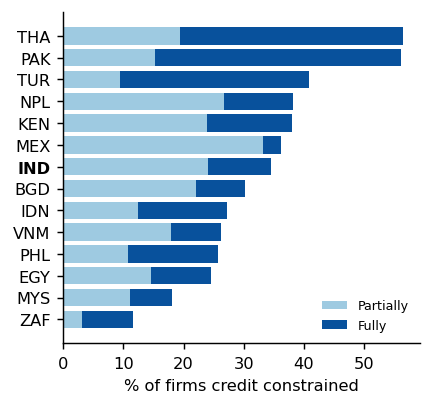

14 peers shown: ['ZAF', 'MYS', 'EGY', 'PHL', 'VNM', 'IDN', 'BGD', 'IND', 'MEX', 'KEN', 'NPL', 'TUR', 'PAK', 'THA']


In [3]:
ind = df[df.iso3 == 'IND'].iloc[0]
share_more = (df.constrained > ind.constrained).mean()
print(f"India {int(ind.year)}: {ind.constrained:.1f}% constrained (fully {ind.fully_constrained:.1f}%, partially {ind.partially_constrained:.1f}%)")
print(f"Sample median: {df.constrained.median():.1f}% | India is less constrained than {share_more*100:.0f}% of survey observations")
peers = ['IND','BGD','PAK','LKA','NPL','IDN','VNM','PHL','THA','MYS','BRA','MEX','ZAF','TUR','EGY','KEN','NGA']
p = df[df.iso3.isin(peers)].sort_values('year').groupby('iso3').tail(1).sort_values('constrained')
fig, ax = plt.subplots(figsize=(3.4, 3.2))
ax.barh(p.iso3, p.partially_constrained, color='#9ecae1', label='Partially')
ax.barh(p.iso3, p.fully_constrained, left=p.partially_constrained, color='#08519c', label='Fully')
for lab in ax.get_yticklabels():
    if lab.get_text() == 'IND': lab.set_fontweight('bold')
ax.set_xlabel('% of firms credit constrained'); ax.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig('figures/fig1_india_vs_peers.png'); plt.show()
print(len(p), 'peers shown:', list(p.iso3))

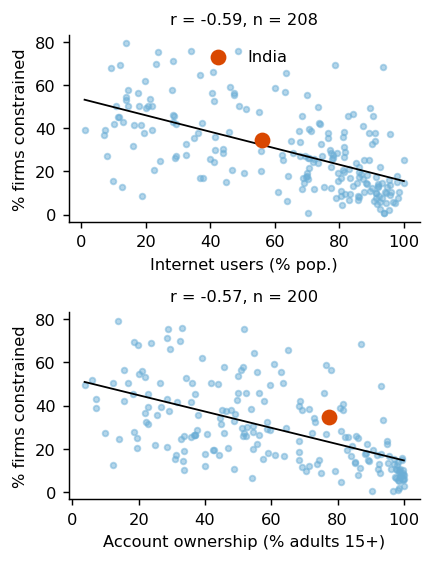

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(3.4, 4.4))
for ax, c, l in zip(axs, ['internet_users', 'account_ownership'], ['Internet users (% pop.)', 'Account ownership (% adults 15+)']):
    d = df.dropna(subset=[c])
    ax.scatter(d[c], d.constrained, s=10, alpha=.5, color='#6baed6')
    di = d[d.iso3 == 'IND']
    ax.scatter(di[c], di.constrained, s=60, color='#d94801', zorder=5, label='India')
    b = np.polyfit(d[c], d.constrained, 1); xs = np.linspace(d[c].min(), d[c].max(), 50)
    ax.plot(xs, np.polyval(b, xs), color='k', lw=1)
    ax.set_xlabel(l); ax.set_ylabel('% firms constrained'); ax.set_title(f'r = {d[c].corr(d.constrained):.2f}, n = {len(d)}', fontsize=9)
axs[0].legend(frameon=False); plt.tight_layout(); plt.savefig('figures/fig2_digital_vs_constraint.png'); plt.show()

## 3. Baseline vs improved models
Baseline: ridge regression on traditional financial-depth and macro variables.
Improved: add digital-access features, then Random Forest / Gradient Boosting.
Validation uses **GroupKFold by country**, so no country appears in both train and test (honest out-of-country accuracy).

In [5]:
base = ['log_gdp_pc', 'private_credit_gdp', 'lending_spread', 'inflation', 'gdp_growth']
digit = ['internet_users', 'mobile_subs', 'log_secure_servers', 'broadband_subs', 'account_ownership']
y, g = df.constrained, df.iso3
cv = GroupKFold(n_splits=5)

def pipe(model, scale=False):
    steps = [SimpleImputer(strategy='median')] + ([StandardScaler()] if scale else [])
    return make_pipeline(*steps, model)

models = {
    'Baseline: Ridge (financial depth)': (pipe(RidgeCV(alphas=np.logspace(-2, 3, 20)), True), base),
    '+ Digital: Ridge': (pipe(RidgeCV(alphas=np.logspace(-2, 3, 20)), True), base + digit),
    '+ Digital: Random Forest': (pipe(RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED)), base + digit),
    '+ Digital: Gradient Boosting': (pipe(GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=.05, subsample=.8, random_state=SEED)), base + digit),
}
rows = []
for name, (m, cols) in models.items():
    p = cross_val_predict(m, df[cols], y, groups=g, cv=cv)
    rows.append((name, r2_score(y, p), mean_absolute_error(y, p)))
res = pd.DataFrame(rows, columns=['Model', 'R2 (country-held-out)', 'MAE (pp)']).round(3)
res

,Model,R2 (country-held-out),MAE (pp)
0,Baseline: Ridge (financial depth),0.505,10.163
1,+ Digital: Ridge,0.506,10.295
2,+ Digital: Random Forest,0.520,9.880
3,+ Digital: Gradient Boosting,0.522,9.990


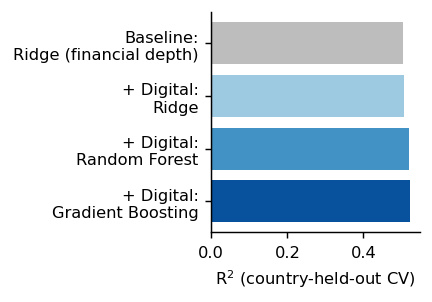

In [6]:
fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.barh(res.Model.str.replace(': ', ':\n'), res['R2 (country-held-out)'], color=['#bdbdbd', '#9ecae1', '#4292c6', '#08519c'])
ax.axvline(0, color='k', lw=.6); ax.set_xlabel('R$^2$ (country-held-out CV)'); ax.invert_yaxis()
plt.tight_layout(); plt.savefig('figures/fig3_model_comparison.png'); plt.show()

## 4. What drives credit constraints? (permutation importance, best model)

Best model: + Digital: Gradient Boosting


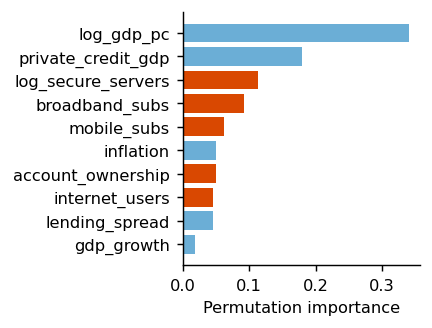

log_gdp_pc            0.340
private_credit_gdp    0.179
log_secure_servers    0.114
broadband_subs        0.092
mobile_subs           0.062
inflation             0.051
account_ownership     0.050
internet_users        0.047
lending_spread        0.046
gdp_growth            0.019
dtype: float64

In [7]:
best_name = res.sort_values('R2 (country-held-out)').iloc[-1].Model
best, cols = models[best_name]
best.fit(df[cols], y)
pi = permutation_importance(best, df[cols], y, n_repeats=30, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=cols).sort_values()
print('Best model:', best_name)
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.barh(imp.index, imp.values, color=['#d94801' if c in digit else '#6baed6' for c in imp.index])
ax.set_xlabel('Permutation importance'); plt.tight_layout(); plt.savefig('figures/fig4_importance.png'); plt.show()
imp.sort_values(ascending=False).round(3)

## 5. India: model prediction and a digital counterfactual
Out-of-country prediction for India (India excluded from training), plus a simple counterfactual that lifts India's digital features to the sample top quartile. Associational, not causal.

In [8]:
tr, ix = df[df.iso3 != 'IND'], df[df.iso3 == 'IND']
m, cols = models[best_name]; m.fit(tr[cols], tr.constrained)
pred = m.predict(ix[cols])[0]
cf = ix[cols].copy()
for c in digit: cf[c] = np.maximum(cf[c], df[c].quantile(.75))
pred_cf = m.predict(cf)[0]
bm, bcols = models['Baseline: Ridge (financial depth)']; bm.fit(tr[bcols], tr.constrained)
pred_base = bm.predict(ix[bcols])[0]
print(f"India actual {ix.constrained.iloc[0]:.1f}% | baseline predicts {pred_base:.1f}% | digital model predicts {pred:.1f}%")
print(f"Counterfactual (digital features at top quartile): {pred_cf:.1f}%  (change {pred_cf-pred:+.1f} pp)")
ix[['year'] + digit].round(1)

India actual 34.5% | baseline predicts 38.8% | digital model predicts 31.8%
Counterfactual (digital features at top quartile): 27.3%  (change -4.5 pp)


,year,internet_users,mobile_subs,log_secure_servers,broadband_subs,account_ownership
78,2022,55.9,80.2,6.6,2.4,77.5


## 6. Limits
- Country-level aggregates (n about 200): ecological, associational evidence; no causal claim.
- India has a single survey observation of the target (2022), so India results are out-of-sample benchmarks, not a time series.
- Numbers here feed the IEEE report and slides.